<a href="https://colab.research.google.com/github/jiaxian-wang/walmart-hurricane-project/blob/main/notebooks/midterm_checkpoint.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

**What you submit: the link to your team's main repo. Only that.** One submission per team. Do not upload separate files.

Put this notebook in the repo (the `notebooks/` folder is fine) and push it, so everything we check is in one place.

**You do not have to fill this all out.** It is a checkpoint, not a finished project. Skip any section you have not started and write "not started" next to it. What we must see is:

1. **Your charter**, committed to the repo
2. **Any progress** you have made, with code that ran and output you can point at

Start with the team setup, then work down the same eight things we listed at Monday's kickoff, as far as you have gotten. This is graded on evidence, not on intentions.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### Team setup

This part is required. Fill it in once for the whole team.

You need:

- Your team name, and every member with a GitHub handle (2 to 4 people)
- A link to your team's **main repo**. This is the one link you submit.
- A link to `CHARTER.md` in that repo, the page on GitHub, not a file on someone's laptop

Nice to have, and also in your charter: this week's notebook owner, your meeting time, and the five worst problems in the data from the profile you ran on Monday. Be specific: "`unit_price` is stored as text and some values start with `$`" beats "prices are messy."

In [1]:
team_setup = {
    'team_name': 'Water Duo',
    'members': [                                  # everyone on the team, 2 to 4 people
        {'name': 'Jiaxian Wang', 'github': 'jiaxian-wang'},
        {'name': 'Anya Chang', 'github': 'enyachang1119-debug'},
    ],
    'repo_url': 'https://github.com/jiaxian-wang/walmart-hurricane-project',                           # your main team repo: https://github.com/...
    'charter_url': 'https://github.com/jiaxian-wang/walmart-hurricane-project/blob/main/CHARTER.md',   # link to CHARTER.md in that repo
    'notebook_owner_this_week': 'Anya Chang',           # nice to have
    'meeting_time': 'Sunday 7pm',                       # nice to have, e.g. 'Tue and Thu 7pm'
    'five_worst_problems': ['TODO'],              # nice to have, five specific problems
}

def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')
    required = {
        'team name': real(t['team_name']),
        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4 and all(real(m['name']) and real(m['github']) for m in t['members']),
        'main repo link': real(t['repo_url']) and t['repo_url'].startswith('https://github.com/'),
        'charter link points at CHARTER.md': real(t['charter_url']) and t['charter_url'].endswith('CHARTER.md'),
    }
    nice = {
        'notebook owner': real(t['notebook_owner_this_week']),
        'meeting time': real(t['meeting_time']),
        'five specific problems': len(t['five_worst_problems']) >= 5 and all(real(p) for p in t['five_worst_problems']),
    }
    if not quiet:
        print('REQUIRED')
        for label, good in required.items():
            print('  PASS' if good else '  FAIL', '-', label)
        print('NICE TO HAVE')
        for label, good in nice.items():
            print('  done' if good else '  not yet', '-', label)
        print()
        print('team setup complete:', all(required.values()))
    return all(required.values())

check_team(team_setup)

REQUIRED
  PASS - team name
  PASS - 2 to 4 members, each with a name and GitHub handle
  PASS - main repo link
  PASS - charter link points at CHARTER.md
NICE TO HAVE
  done - notebook owner
  done - meeting time
  not yet - five specific problems

team setup complete: True


True

Now show that the charter is actually committed. This is required. Run the next cell and leave its output in the notebook. Point `REPO_PATH` at your local clone of the team repo. If it prints a line like `a1b2c3d Add team charter`, you are done. If it prints "no commits found," the charter is not in the repo yet, so commit it and push before you submit.

In [2]:
import subprocess

REPO_PATH = "/content/walmart-hurricane-project"

result = subprocess.run(
    ['git', '-C', REPO_PATH, 'log', '--oneline', '--', 'CHARTER.md'],
    capture_output=True, text=True
)
print(result.stdout.strip() or 'no commits found for CHARTER.md')

afe6d66 Add files via upload


### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [3]:
# TODO
from pathlib import Path  # import a tool for working with file paths
import pandas as pd  # import pandas for working with tables

def normalize_store_id(values):  # define a function to standardize store ids
    return (values.astype("string").str.strip().str.upper()  # convert to text, trim spaces, and capitalize
            .str.replace(r"^FL[-_ ]?(\d{3})$", r"FL-\1", regex=True))  # standardize matching ids to FL-###

def parse_timestamps(values):  # define a function to parse different date formats
    parsed = pd.Series(pd.NaT, index=values.index, dtype="datetime64[ns]")  # create an empty datetime series
    for fmt in ["%Y-%m-%dT%H:%M:%S", "%Y-%m-%d %H:%M:%S",  # include year-first formats with seconds
                "%m/%d/%Y %H:%M", "%m-%d-%Y %H:%M:%S", "%d-%b-%Y %H:%M"]:  # include the other observed formats
        remaining = parsed.isna()  # identify timestamps that have not been parsed
        parsed.loc[remaining] = pd.to_datetime(  # try parsing the remaining timestamps
            values.loc[remaining], format=fmt, errors="coerce")  # leave unsuccessful conversions as missing
    return parsed  # return the parsed timestamps

def clean_sales(raw):  # define a function to clean the transaction data
    log = []  # create a list to store cleaning decisions

    def record(step, decision, affected, removed=0):  # define a helper to record each decision
        log.append({"step": step, "decision": decision,  # store the step name and explanation
                    "rows_affected": int(affected), "rows_removed": int(removed)})  # store the affected and removed counts
    df = raw.drop_duplicates().copy()  # remove exact duplicates and create a separate dataframe
    removed = len(raw) - len(df)  # calculate the number of duplicate rows removed
    record("duplicates", "Remove exact duplicate rows only", removed, removed)  # log duplicate removal
    price_text = df["unit_price"].astype("string")  # store the original prices as text
    price_clean = (price_text.str.strip().str.replace("$", "", regex=False)  # remove surrounding spaces and dollar signs
                   .str.replace(",", "", regex=False))  # remove commas from prices
    df["unit_price"] = pd.to_numeric(price_clean, errors="coerce")  # convert prices to numbers and invalid values to missing
    record("price format", "Remove dollar signs and whitespace; convert to numeric",  # describe price formatting
           price_text.ne(price_clean).sum())  # count prices whose text changed
    df["invalid_price"] = df["unit_price"].isna()  # flag missing or unparseable prices
    record("invalid price", "Keep and flag missing or unparseable prices",  # describe the invalid-price policy
           df["invalid_price"].sum())  # count flagged prices

    df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")  # convert quantities to numbers
    df["negative_quantity"] = df["quantity"].lt(0)  # flag quantities below zero without removing them
    record("negative quantity", "Keep signed values and flag; meaning needs confirmation",  # describe the negative-quantity policy
           df["negative_quantity"].sum())  # count negative quantities

    df["timestamp_raw"] = df["timestamp"]  # preserve the original timestamp values
    df["timestamp"] = parse_timestamps(df["timestamp"])  # convert timestamps using the supported formats
    df["missing_timestamp"] = df["timestamp"].isna()  # flag missing or unparseable timestamps
    record("timestamp parsing", "Parse five explicit date formats",  # describe timestamp conversion
           df["timestamp"].notna().sum())  # count successfully parsed timestamps
    record("missing timestamp", "Keep and flag; exclude explicitly from date-based analyses",  # record the policy for later date-based analysis
           df["missing_timestamp"].sum())  # count rows that still lack timestamps

    original_ids = df["store_id"].copy()  # preserve store ids for comparison
    df["store_id"] = normalize_store_id(df["store_id"])  # standardize transaction store ids
    record("store_id", "Normalize case, spaces and separators to FL-###",  # describe store id cleaning
           original_ids.ne(df["store_id"]).sum())  # count store ids that changed

    print(f"Before: {len(raw):,}")  # display the original transaction count
    print(f"After: {len(df):,}")  # display the cleaned transaction count
    print(f"Rows removed: {len(raw) - len(df):,}")  # display the number of removed transactions
    return df, pd.DataFrame(log)  # return cleaned transactions and the decision log


def clean_stores(raw):  # define a function to clean the store data
    df = raw.copy()  # create a copy to preserve the input data
    df["store_id"] = normalize_store_id(df["store_id"])  # standardize store ids for matching
    df["state"] = df["state"].str.strip().replace({"Florida": "FL", "Fla.": "FL"})  # standardize state names
    df["region"] = df["region"].str.strip()  # remove surrounding spaces from region names
    for col in ["latitude", "longitude"]:  # loop through both coordinate columns
        df[col] = pd.to_numeric(df[col], errors="coerce")  # convert coordinates to numbers and invalid values to missing
    df = df.drop_duplicates()  # remove identical store records after standardization
    if df["store_id"].duplicated().any():  # check whether different records share a store id
        raise ValueError("Conflicting store records need manual review")  # stop if store records conflict
    print(f"Store rows: {len(raw)} -> {len(df)}")  # display store counts before and after cleaning
    return df  # return the cleaned store data

def run_checkpoint(data_dir="."):  # define the workflow using the current folder by default
    data_dir = Path(data_dir)  # convert the folder location to a path object
    raw_sales = pd.read_csv(data_dir / "walmart_transactions.csv", dtype="string")  # load transactions as text
    raw_stores = pd.read_csv(data_dir / "store_locations.csv", dtype="string")  # load stores as text
    cleaned_sales, decision_log = clean_sales(raw_sales)  # clean transactions and collect their decision log
    cleaned_stores = clean_stores(raw_stores)  # clean the store information
    sales_with_stores = cleaned_sales.merge(  # attach store information to transactions
        cleaned_stores, on="store_id", how="left", validate="many_to_one", indicator=True)  # retain all transactions and require unique store matches
    print("Unmatched store IDs:", int(sales_with_stores["_merge"].eq("left_only").sum()))  # display the number of transactions without a store match
    print("\nDecision log (Section 2):")  # print a heading for the decision log
    print(decision_log.to_string(index=False))  # display the log without row index numbers
    return cleaned_sales, cleaned_stores, decision_log, sales_with_stores  # return the four results

cleaned_sales, cleaned_stores, decision_log, sales_with_stores = run_checkpoint()  # run the workflow and save its results

Before: 25,562
After: 25,532
Rows removed: 30
Store rows: 14 -> 12
Unmatched store IDs: 0

Decision log (Section 2):
             step                                                   decision  rows_affected  rows_removed
       duplicates                           Remove exact duplicate rows only             30            30
     price format     Remove dollar signs and whitespace; convert to numeric           4329             0
    invalid price                Keep and flag missing or unparseable prices              0             0
negative quantity    Keep signed values and flag; meaning needs confirmation            130             0
timestamp parsing                           Parse five explicit date formats          24648             0
missing timestamp Keep and flag; exclude explicitly from date-based analyses            884             0
         store_id            Normalize case, spaces and separators to FL-###           4345             0


### 2 — Your decision log
**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [4]:
# TODO: print or display your decision log
with pd.option_context("display.max_colwidth", None):
    display(decision_log)

,step,decision,rows_affected,rows_removed
0,duplicates,Remove exact duplicate rows only,30,30
1,price format,Remove dollar signs and whitespace; convert to numeric,4329,0
2,invalid price,Keep and flag missing or unparseable prices,0,0
3,negative quantity,Keep signed values and flag; meaning needs confirmation,130,0
4,timestamp parsing,Parse five explicit date formats,24648,0
5,missing timestamp,Keep and flag; exclude explicitly from date-based analyses,884,0
6,store_id,"Normalize case, spaces and separators to FL-###",4345,0


_We removed 30 exact duplicate rows to avoid double-counting transactions. We cleaned the price formatting in 4,329 rows and converted prices to numeric values; no prices failed conversion. We also standardized 4,345 store IDs so transactions could match the store data. We successfully parsed 24,648 timestamps. The remaining 884 transactions were retained and flagged because their timestamps were missing. These rows will be excluded from date-based analyses rather than assigned estimated dates. We retained and flagged 130 negative quantities because their meaning has not been confirmed. We did not change them to positive values or assume they were returns. This decision still needs team review. The affected-row counts describe individual cleaning steps and may overlap, so they should not be added together as a count of unique transactions. For the store data, we standardized 2 store IDs, changed 4 state names to FL, and removed extra spaces from 1 region name. These changes make the data consistent and help match stores with transactions. We converted latitude and longitude to numeric values for 13 records. We kept the Tallahassee store’s missing coordinates rather than guessing its location; these coordinates still need verification before retrieving weather for that store. After standardization, we removed 2 duplicate store records to prevent duplicate matches during the join. This reduced the store table from 14 records to 12 unique stores. All cleaned transactions successfully matched a store record._

### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [5]:
# TODO

# Package sizes differ, so original SKUs are preserved.
sku_mapping = {
    "PT-12": "Pop-Tarts Strawberry",
    "SKU#459812": "Pop-Tarts Strawberry",
    "POPTART-STRAW": "Pop-Tarts Strawberry",
    "PT_STRAWBERRY": "Pop-Tarts Strawberry",
}

# Unreviewed products keep their original SKU as their identifier.
cleaned_sales["canonical_product"] = (cleaned_sales["sku"].map(sku_mapping).fillna(cleaned_sales["sku"]))
before = cleaned_sales["sku"].nunique()
after = cleaned_sales["canonical_product"].nunique()

group_sizes = (cleaned_sales.groupby("canonical_product")["sku"].nunique().sort_values(ascending=False))

print("Original distinct SKUs:", before)
print("Current canonical groups (partial):", after)
print("Largest group:", group_sizes.index[0])
print("SKUs in largest group:", group_sizes.iloc[0])

mapping_table = pd.DataFrame(sku_mapping.items(),columns=["original_sku", "canonical_product"])
display(mapping_table)

print(
    "Status: partial. Four strawberry Pop-Tarts SKUs are grouped "
    "at the product-family level. Package sizes still need review; "
    "other SKUs remain separate."
)

Original distinct SKUs: 45
Current canonical groups (partial): 42
Largest group: Pop-Tarts Strawberry
SKUs in largest group: 4


,original_sku,canonical_product
0,PT-12,Pop-Tarts Strawberry
1,SKU#459812,Pop-Tarts Strawberry
2,POPTART-STRAW,Pop-Tarts Strawberry
3,PT_STRAWBERRY,Pop-Tarts Strawberry


Status: partial. Four strawberry Pop-Tarts SKUs are grouped at the product-family level. Package sizes still need review; other SKUs remain separate.


### 4 — One working weather API call

**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [6]:
import time  # import a tool for waiting between attempts
import requests  # import a tool for making api requests
import pandas as pd  # import pandas for working with tables

def fetch_weather():  # define a function to request daily weather
    url = "https://archive-api.open-meteo.com/v1/archive"  # set the historical weather endpoint
    params = {  # define the location, dates, and weather variables
        "latitude": 28.5383,  # use the Orlando store latitude
        "longitude": -81.3792,  # use the Orlando store longitude
        "start_date": "2024-09-01",  # set the first date
        "end_date": "2024-09-30",  # set the last date
        "daily": "temperature_2m_mean,precipitation_sum,wind_speed_10m_max",  # request daily temperature, rain, and wind
        "timezone": "America/New_York",  # request days based on Orlando local time
        "temperature_unit": "celsius",  # request temperature in degrees Celsius
        "wind_speed_unit": "kmh",  # request wind speed in kilometers per hour
        "precipitation_unit": "mm",  # request precipitation in millimeters
    }  # finish the request parameters

    for attempt in range(3):  # allow up to three attempts
        try:  # try sending the request
            response = requests.get(url, params=params, timeout=30)  # wait at most 30 seconds for a response
            response.raise_for_status()  # raise an error for an unsuccessful http response
            data = response.json()  # parse the response into a dictionary
            break  # stop retrying after a successful request
        except requests.exceptions.RequestException as error:  # catch request failures
            print(f"Attempt {attempt + 1} failed: {error}")  # show the actual error
            if attempt == 2:  # check whether all attempts have failed
                raise  # stop and preserve the final error
            time.sleep(2 ** attempt)  # wait one second and then two seconds before retrying

    weather = pd.DataFrame(data["daily"])  # convert daily weather into a dataframe
    weather = weather.rename(columns={"time": "date"})  # rename the daily time column
    weather["date"] = pd.to_datetime(weather["date"])  # parse the local calendar dates
    weather["store_id"] = "FL-239"  # identify the store represented by these coordinates
    weather["timezone"] = params["timezone"]  # record the timezone used for daily aggregation
    weather["source"] = "Open-Meteo Historical Weather API"  # record the data source
    print("Request URL:", response.url)  # show the actual api request
    print("Units:", data["daily_units"])  # show the units returned by the api
    return weather  # return the parsed weather data

weather_df = fetch_weather()  # request and parse the weather data
print("Weather rows:", len(weather_df))  # display the number of returned days
display(weather_df)  # display the weather table

Request URL: https://archive-api.open-meteo.com/v1/archive?latitude=28.5383&longitude=-81.3792&start_date=2024-09-01&end_date=2024-09-30&daily=temperature_2m_mean%2Cprecipitation_sum%2Cwind_speed_10m_max&timezone=America%2FNew_York&temperature_unit=celsius&wind_speed_unit=kmh&precipitation_unit=mm
Units: {'time': 'iso8601', 'temperature_2m_mean': '°C', 'precipitation_sum': 'mm', 'wind_speed_10m_max': 'km/h'}
Weather rows: 30


,date,temperature_2m_mean,precipitation_sum,wind_speed_10m_max,store_id,timezone,source
0,2024-09-01,25.9,6.4,18.7,FL-239,America/New_York,Open-Meteo Historical Weather API
1,2024-09-02,25.9,22.0,12.7,FL-239,America/New_York,Open-Meteo Historical Weather API
2,2024-09-03,26.2,32.7,20.6,FL-239,America/New_York,Open-Meteo Historical Weather API
3,2024-09-04,26.2,21.1,12.6,FL-239,America/New_York,Open-Meteo Historical Weather API
4,2024-09-05,25.8,20.7,15.2,FL-239,America/New_York,Open-Meteo Historical Weather API
5,2024-09-06,26.4,4.3,8.0,FL-239,America/New_York,Open-Meteo Historical Weather API
6,2024-09-07,25.8,4.5,12.1,FL-239,America/New_York,Open-Meteo Historical Weather API
7,2024-09-08,26.1,57.4,10.5,FL-239,America/New_York,Open-Meteo Historical Weather API
8,2024-09-09,25.3,20.9,10.4,FL-239,America/New_York,Open-Meteo Historical Weather API
9,2024-09-10,25.9,14.7,12.0,FL-239,America/New_York,Open-Meteo Historical Weather API


This request retrieves daily weather for the Orlando store (FL-239). Temperature is measured in °C, precipitation in mm, and maximum wind speed in km/h. The data comes from the Open-Meteo Historical Weather API, which provides historical weather estimates based on reanalysis data.

Weather days is use the America/New_York timezone. The date column represents local calendar dates, not UTC timestamps. Before joining, we will confirm the timezone of the sales timestamps and convert them to Orlando local time if necessary. We will then aggregate Orlando sales by local date and join on store_id and date. Transactions with missing timestamps will be excluded from this date-based analysis.

### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

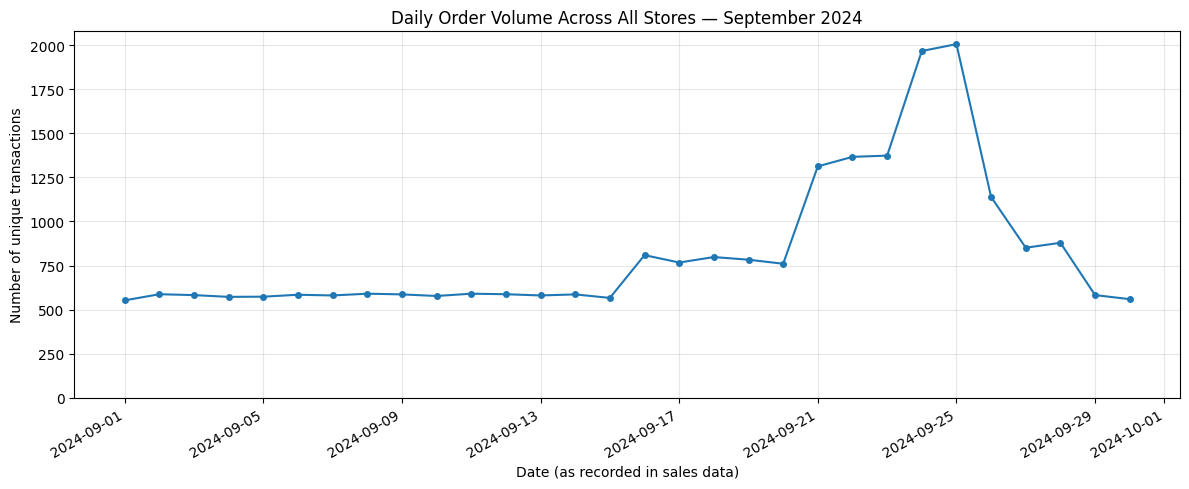

Rows excluded for missing timestamps: 884
Highest-volume date: 2024-09-25
Highest daily order count: 2007
Days with zero recorded orders: 0


In [7]:
import matplotlib.pyplot as plt  # import plotting tools

dated_sales = cleaned_sales.dropna(subset=["timestamp"]).copy()  # exclude transactions with missing timestamps
dated_sales["date"] = dated_sales["timestamp"].dt.normalize()  # extract each transaction's calendar date

daily_orders = dated_sales.groupby("date")["transaction_id"].nunique()  # count distinct transaction ids each day
date_range = pd.date_range(daily_orders.index.min(), daily_orders.index.max())  # create the complete observed date range
daily_orders = daily_orders.reindex(date_range, fill_value=0)  # show days with no recorded orders as zero
daily_orders.index.name = "date"  # name the date index

fig, ax = plt.subplots(figsize=(12, 5))  # create the chart
ax.plot(daily_orders.index, daily_orders.values, marker="o", markersize=4)  # plot daily transaction counts
ax.set_title("Daily Order Volume Across All Stores — September 2024")  # add a descriptive title
ax.set_xlabel("Date (as recorded in sales data)")  # label the horizontal axis
ax.set_ylabel("Number of unique transactions")  # label the vertical axis
ax.set_ylim(bottom=0)  # start the vertical axis at zero
ax.grid(alpha=0.3)  # add light grid lines
fig.autofmt_xdate()  # rotate date labels for readability
plt.tight_layout()  # adjust spacing
plt.show()  # display the chart

print("Rows excluded for missing timestamps:", len(cleaned_sales) - len(dated_sales))  # report excluded rows
print("Highest-volume date:", daily_orders.idxmax().strftime("%Y-%m-%d"))  # display the busiest date
print("Highest daily order count:", daily_orders.max())  # display the highest count
print("Days with zero recorded orders:", int(daily_orders.eq(0).sum()))  # check for empty days

This chart counts unique transaction IDs per day across all stores. We excluded 884 transactions with missing timestamps and retained transactions with negative quantities because their meaning is still under review. Daily order volume stayed around 550–600 transactions during the first half of September, increased after September 15, and rose sharply around September 21–25. It peaked at 2,007 transactions on September 25 before returning to roughly its early-month level by September 29–30. No dates had zero recorded orders. The pattern suggests a temporary increase in recorded order volume, but it does not establish that the hurricane caused it. We still need to confirm the sales timezone, examine differences across stores, and check whether missing timestamps or other data issues affect the pattern.

### 6 — Self-check

Fill in what you have and leave the rest. **The required items are the team setup and the charter.** Everything else is progress we want to see, not a pass or fail. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [8]:
required = {
    'team_setup_complete': check_team(team_setup, quiet=True),   # from the team setup section
    'charter_committed': True,         # TODO: True once CHARTER.md shows in the git log above
}

progress = {
    'rows_after_cleaning': len(cleaned_sales),  # count cleaned transactions
    'decisions_logged': len(decision_log),  # count recorded decisions
    'canonical_products': cleaned_sales["canonical_product"].nunique(),  # count current product groups
    'weather_api_rows': len(weather_df),  # count the returned weather rows
    'notebook_runs_clean': True,  # change to true after restart and run all succeeds
}

def is_done(value):
    return not (value is None or value is False
                or (isinstance(value, str) and value.startswith('TODO')))

def check(required, progress):
    print('REQUIRED')
    for label, value in required.items():
        print('  PASS' if is_done(value) else '  FAIL', '-', label, '=', value)
    print('PROGRESS (fill in what you have)')
    for label, value in progress.items():
        print('  done' if is_done(value) else '  not yet', '-', label, '=', value)
    ok = all(is_done(v) for v in required.values())
    print()
    print('required items complete:', ok)
    print('progress items done:', sum(is_done(v) for v in progress.values()), 'of', len(progress))
    return ok

check(required, progress)

REQUIRED
  PASS - team_setup_complete = True
  PASS - charter_committed = True
PROGRESS (fill in what you have)
  done - rows_after_cleaning = 25532
  done - decisions_logged = 7
  done - canonical_products = 42
  done - weather_api_rows = 30
  done - notebook_runs_clean = True

required items complete: True
progress items done: 5 of 5


True

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

**Biggest risk:** _We may incorrectly match weather data to sales because 884 transactions have missing timestamps and the sales timezone has not yet been confirmed. This could affect our weather correlation analysis._

**Plan, with an owner and a date:**
_By Oct 28th, Anya Chang will review the missing timestamps and document how they will be handled in time-based analysis. Jiaxian Wang will check the weather API timezone and test the weather-to-sales join for one store._

### 8 — Where each question stands

**TODO:** mark each of the five questions. These owners must match the question owners table in your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | _draft answer_ | _Anya Chang_ |
| Q2 SKU consolidation | _in progress | _Jiaxian Wang_ |
| Q3 weather correlation | _in progress_ | _Anya Chang_ |
| Q4 store and geography | _not started_ | _Jiaxian Wang_ |
| Q5 signal or artifact | _not started_ | _Anya Chang_ |

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.